In [1]:
!pip install sympy==1.10.1

import numpy as np
import sympy
from sympy.utilities.lambdify import lambdify
import matplotlib.pyplot as plt
import scipy.optimize

plt.rc('font', size=15)
plt.rc('figure', figsize=(16, 9))

In [2]:
t0 = 1;
x0 = 1;
T = 5;

In [3]:
t = sympy.symbols('t')
x = sympy.Function('x')

eq = sympy.Eq(
        sympy.Derivative(x(t), t),
        x(t)*t**(-1) - 5*t**2*x(t)**3
)

eq

Eq(Derivative(x(t), t), -5*t**2*x(t)**3 + x(t)/t)

In [4]:
sol = sympy.dsolve(eq, ics ={x(t0) : x0})
dokl = lambdify(t, sol.rhs)
dokl

<function _lambdifygenerated(t)>

In [5]:
f = lambdify((t, x(t)), eq.rhs)

In [6]:
td = np.linspace(t0, T, 1000);
xd = dokl(td);

In [7]:
def heun(f, t0, T, N, x0):
    t, h = np.linspace(t0, T, N+1, retstep=True);
    
    x = np.zeros(t.shape);
    x[0]=x0;
    
    
    for n in range(N):
        k1 = f(t[n], x[n])
        k2 = f(t[n] + (1/3)*h, x[n] + h*(1/3)*k1)
        k3 = f(t[n] + (2/3)*h, x[n] + h*(0*k1 + (2/3)*k2))
        
        x[n+1] = x[n] + h*((1/4)*k1 + 0*k2 + (3/4)*k3)

    return (t, x);

N =   15, Blad = 4.396e-01
N =   23, Blad = 1.134e-01, Stosunek: 3.88
N =   39, Blad = 2.071e-02, Stosunek: 5.47
N =   71, Blad = 2.690e-03, Stosunek: 7.7
N =  135, Blad = 3.054e-04, Stosunek: 8.81
N =  263, Blad = 3.587e-05, Stosunek: 8.51
N =  519, Blad = 4.326e-06, Stosunek: 8.29
N = 1031, Blad = 5.305e-07, Stosunek: 8.15
N = 2055, Blad = 6.567e-08, Stosunek: 8.08
N = 4103, Blad = 8.169e-09, Stosunek: 8.04
N = 8199, Blad = 1.019e-09, Stosunek: 8.02
N = 16391, Blad = 1.272e-10, Stosunek: 8.01
N = 32775, Blad = 1.589e-11, Stosunek: 8.0
N = 65543, Blad = 1.985e-12, Stosunek: 8.0


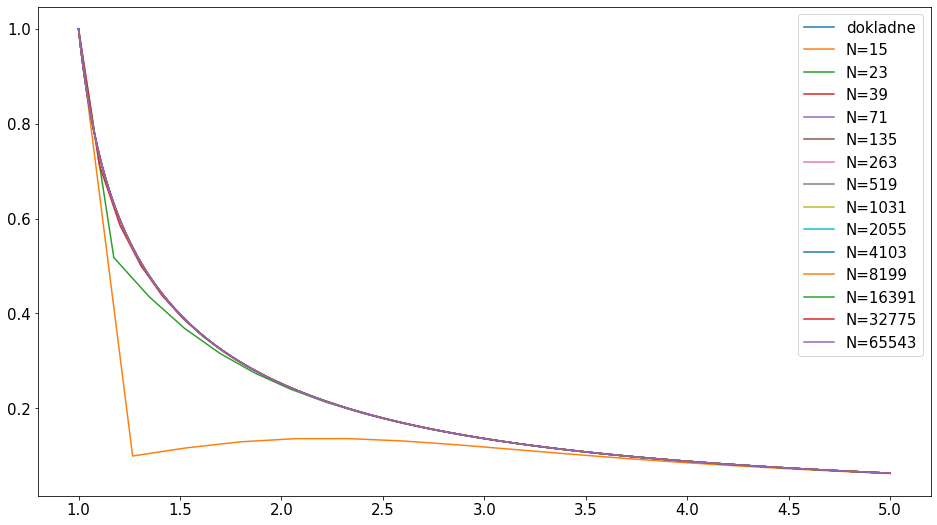

In [8]:
plt.plot(td, xd, label="dokladne")
curr_error=None;

for N in [7+2**k for k in range(3,17)]:
    t, x = heun(f, t0, T, N, x0)
    plt.plot(t, x, label=f"N={N}")
    
    prev_error, curr_error = curr_error, max(np.abs(x-dokl(t)))
    if(prev_error is None):
        print(f'N = {N:4d}, Blad = {curr_error:.3e}')
    else:
        print(f'N = {N:4d}, Blad = {curr_error:.3e}, Stosunek: {prev_error/curr_error:.3}')

plt.legend()